# V3: Model Explainability

This notebook explains the predictions made by the final tuned XGBoost model from V2.

The analysis includes:

- Global feature importance
- SHAP-based feature importance
- Visualization of the features most associated with fraud predictions

In [1]:
from pathlib import Path

import joblib
import pandas as pd
import matplotlib.pyplot as plt
import shap

# Paths relative to fraud-detection-v3/notebooks/
DATA_PATH = Path("../../data/raw/creditcard.csv")
MODEL_PATH = Path("../../fraud-detection-v2/models/xgboost_tuned.joblib")
REPORTS_PATH = Path("../reports")

REPORTS_PATH.mkdir(parents=True, exist_ok=True)

# Load the raw dataset
df = pd.read_csv(DATA_PATH)

# Separate features and target
X = df.drop(columns=["Class"])
y = df["Class"]

# Load the saved V2 model package
model_package = joblib.load(MODEL_PATH)

# The V2 file contains the model, threshold, and feature names
model = model_package["model"]
threshold = model_package["threshold"]
feature_names = model_package["feature_names"]

# Ensure the feature order matches the saved model
X = X[feature_names]

print(f"Dataset shape: {X.shape}")
print(f"Fraud cases: {y.sum()}")
print(f"Classification threshold: {threshold}")

Dataset shape: (284807, 30)
Fraud cases: 492
Classification threshold: 0.5


## Global Feature Importance

XGBoost provides a built-in feature-importance score based on how useful each feature was when creating the decision trees.

This shows which features the trained model relied on most overall. It does not explain the direction of the effect, so SHAP analysis will be used later for more detailed explanations.

In [2]:
# Extract built-in XGBoost feature importance
feature_importance = pd.DataFrame(
    {
        "Feature": feature_names,
        "Importance": model.feature_importances_,
    }
).sort_values("Importance", ascending=False)

# Display the top 20 features
display(feature_importance.head(20))

,Feature,Importance
14,V14,0.540237
12,V12,0.067898
4,V4,0.065128
17,V17,0.031180
8,V8,0.026136
20,V20,0.021026
10,V10,0.018330
29,Amount,0.017963
7,V7,0.016816
26,V26,0.016656


In [3]:
feature_importance.to_csv(
    REPORTS_PATH / "xgboost_feature_importance.csv",
    index=False,
)

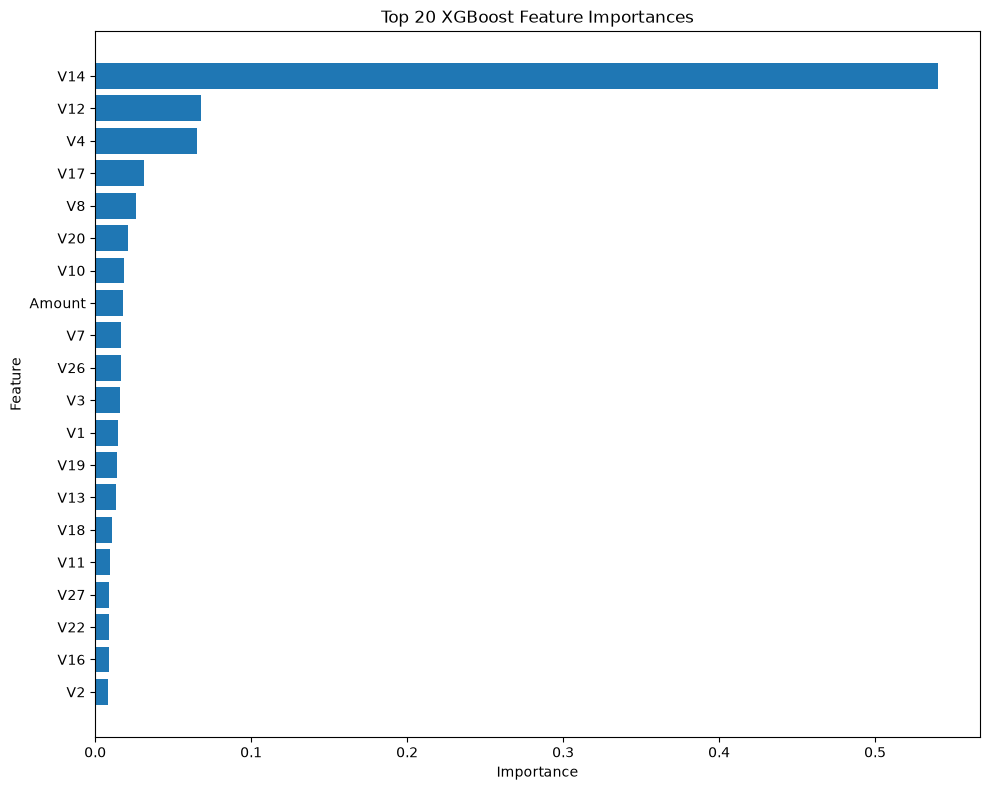

In [4]:
top_features = feature_importance.head(20).sort_values("Importance")

plt.figure(figsize=(10, 8))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 20 XGBoost Feature Importances")
plt.tight_layout()

plt.savefig(
    REPORTS_PATH / "xgboost_feature_importance.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## SHAP-Based Model Explainability

SHAP values describe how individual features influence the model's predictions. The summary plot presents the features with the greatest overall influence across a representative sample of transactions.

Positive SHAP values indicate that a feature contributes toward a fraud prediction, while negative values contribute toward a legitimate-transaction prediction.

In [5]:
X_shap = X.sample(
    n=min(5000, len(X)),
    random_state=42,
)

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_shap)

if isinstance(shap_values, list):
    shap_values = shap_values[1]

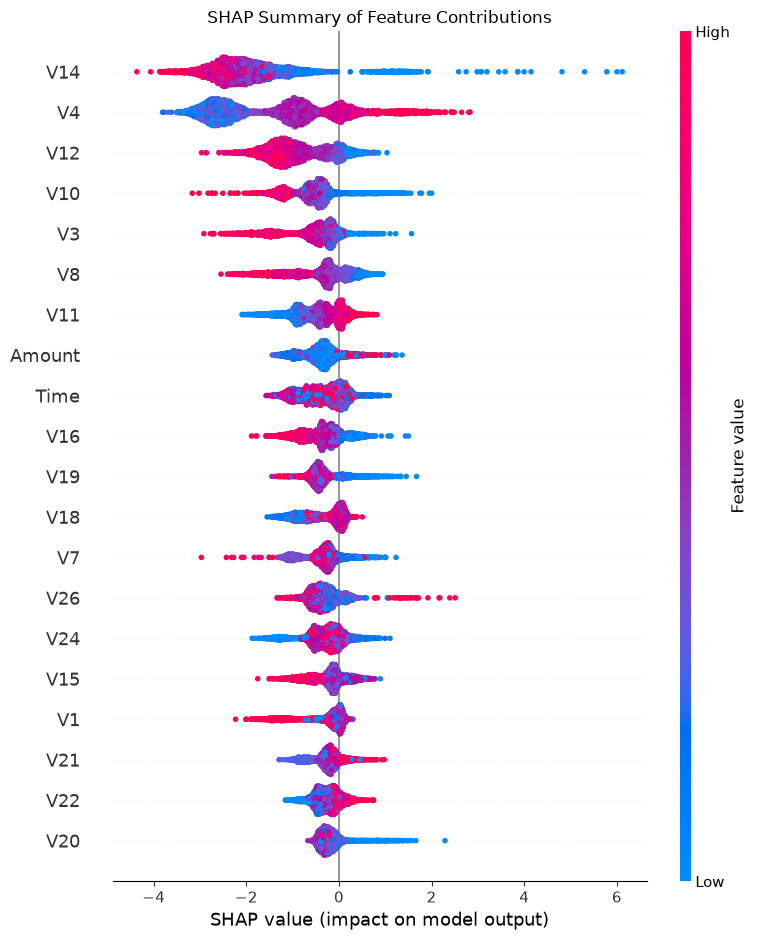

In [6]:
shap.summary_plot(
    shap_values,
    X_shap,
    max_display=20,
    show=False,
)

plt.title("SHAP Summary of Feature Contributions")
plt.tight_layout()

plt.savefig(
    REPORTS_PATH / "shap_summary_plot.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### Interpretation

The SHAP summary plot shows the features that have the greatest influence on the model's predictions. Features are ranked by their mean absolute SHAP value, with the most influential features shown at the top.

V14 has the strongest overall influence on the model's predictions, followed by V4, V12, V10, and V3. The horizontal position of each point represents its effect on the prediction: points to the right increase the model's fraud score, while points to the left decrease it.

Color represents the feature value. Red indicates higher feature values and blue indicates lower feature values. The distribution of colors across the horizontal axis shows that the relationship between feature values and fraud predictions is not always linear.

These results indicate that the model relies primarily on a small group of transformed transaction features when distinguishing fraudulent transactions from legitimate transactions. SHAP provides a more detailed explanation than the built-in XGBoost importance scores because it shows both feature importance and the direction of each feature's contribution.

In [7]:
shap_importance = (
    pd.DataFrame(
        {
            "Feature": X_shap.columns,
            "Mean Absolute SHAP": abs(shap_values).mean(axis=0),
        }
    )
    .sort_values("Mean Absolute SHAP", ascending=False)
    .reset_index(drop=True)
)

display(shap_importance.head(20))

shap_importance.to_csv(
    REPORTS_PATH / "shap_feature_importance.csv",
    index=False,
)

,Feature,Mean Absolute SHAP
0,V14,2.053116
1,V4,1.534259
2,V12,0.921338
3,V10,0.662663
4,V3,0.563645
5,V8,0.527868
6,V11,0.490869
7,Amount,0.444036
8,Time,0.437386
9,V16,0.430767


### SHAP Feature Importance Results

The SHAP results confirm that V14 is the most influential feature in the tuned XGBoost model, with a mean absolute SHAP value of 2.0531. V4 is the second most influential feature, followed by V12, V10, and V3.

These values measure the average magnitude of each feature's contribution to the model output. A higher mean absolute SHAP value indicates that the feature has a greater influence on the model's predictions, regardless of whether that influence increases or decreases the predicted fraud score.

The results are consistent with the built-in XGBoost feature-importance analysis, which also identified V14 as the most important feature. This consistency increases confidence that the model's predictions are primarily driven by a small number of influential transaction features.

The complete SHAP feature-importance results are saved in `reports/shap_feature_importance.csv`.

## Individual Prediction Explanation

Global SHAP analysis describes the overall behavior of the model. This section examines one fraudulent transaction in detail.

The waterfall plot shows how each feature moves the model output away from its baseline prediction. Features that push the prediction higher contribute toward fraud, while features that push it lower contribute toward a legitimate-transaction prediction.

In [8]:
fraud_positions = (y.loc[X_shap.index] == 1).to_numpy()

if fraud_positions.any():
    selected_position = fraud_positions.argmax()
else:
    selected_position = 0

selected_index = X_shap.index[selected_position]
selected_features = X_shap.iloc[selected_position]

selected_prediction_probability = model.predict_proba(
    selected_features.to_frame().T
)[0, 1]

print(f"Transaction index: {selected_index}")
print(f"Actual class: {y.loc[selected_index]}")
print(f"Predicted fraud probability: {selected_prediction_probability:.4f}")
print(f"Predicted class: {int(selected_prediction_probability >= threshold)}")

Transaction index: 43428
Actual class: 1
Predicted fraud probability: 1.0000
Predicted class: 1


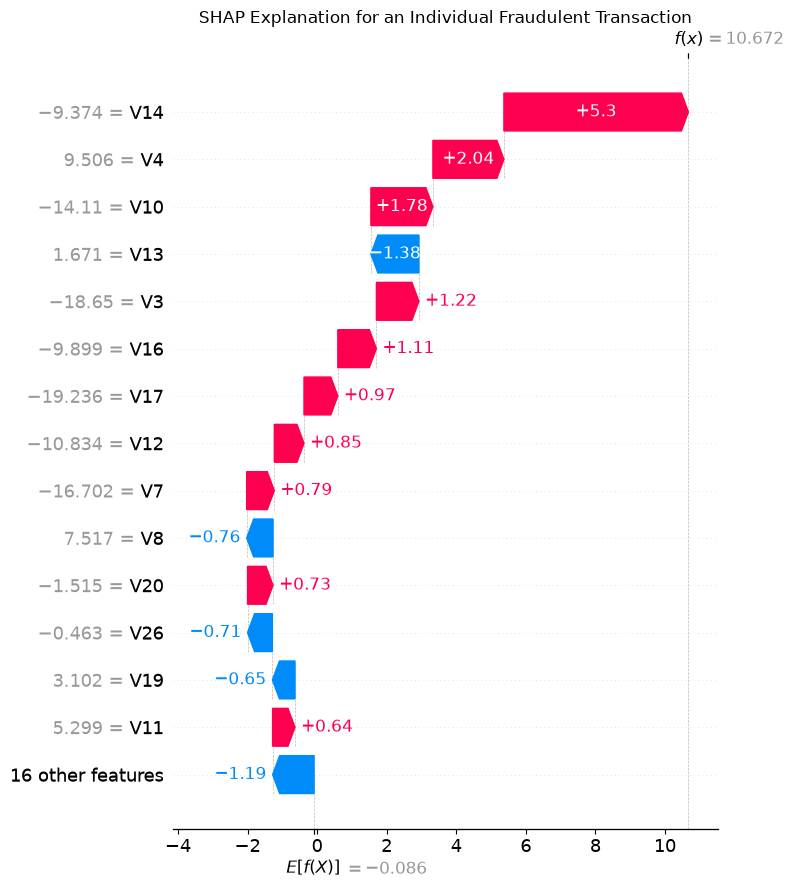

In [9]:
expected_value = explainer.expected_value

if isinstance(expected_value, (list, tuple)):
    expected_value = expected_value[1]
elif hasattr(expected_value, "ndim") and expected_value.ndim > 0:
    expected_value = expected_value[-1]

local_explanation = shap.Explanation(
    values=shap_values[selected_position],
    base_values=expected_value,
    data=selected_features.to_numpy(),
    feature_names=X_shap.columns.tolist(),
)

shap.plots.waterfall(
    local_explanation,
    max_display=15,
    show=False,
)

plt.title("SHAP Explanation for an Individual Fraudulent Transaction")
plt.tight_layout()

plt.savefig(
    REPORTS_PATH / "shap_individual_prediction.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### Individual Prediction Interpretation

The waterfall plot explains a transaction that the model classified as fraudulent. The model output is strongly positive, indicating substantial evidence in favor of the fraud class.

V14 is the largest contributor to the prediction, followed by V4 and V10. These features substantially increase the model's fraud score. Other features, including V13, V8, V26, and V19, reduce the score, but their combined effect is not large enough to change the final classification.

This example demonstrates how individual transactions can receive a fraud prediction because of the combined influence of several features. The explanation is model-specific and describes the factors that influenced this particular prediction; it does not imply that any single feature independently causes fraud.